# La alimentación de Rosin-Rammler en la malla de tamices: qué hacen x63 y m con el F80

**Pregunta:** ¿Cómo fijan los dos parámetros de Rosin-Rammler de una alimentación el F80 que ve el motor del chancador, y por qué ese F80 no es el que da la fórmula de los textos?

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** el notebook 01 del tema 01-getting-started
- **Tiempo de lectura:** unos 25 minutos

## Objetivos

Al terminar este notebook usted puede:

- escribir la ley de Rosin-Rammler, decir qué significan x63 y m, y dibujar la alimentación que describen;
- discretizar la ley en la malla de tamices del motor y leer F80 por interpolación;
- comparar ese F80 con el de forma cerrada que entrega un oráculo que no comparte código con el motor;
- explicar la diferencia entre ambos: la malla del motor termina en 256 mm, y la masa sobre ese tamaño no está en la alimentación.

## Preparación

El mismo entorno que el resto del conjunto: numpy para los arreglos, matplotlib para las figuras.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Importan dos grupos. El generador de alimentación y las utilidades de tamices vienen de los módulos del motor. La ley de forma cerrada viene de `data-pipeline/pipeline/oracles.py`, que enuncia las relaciones de Rosin-Rammler del texto y no comparte código con el motor; sus funciones se importan con otros nombres para no confundirlas con las del motor.

In [1]:
# Imprima las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.crusher.feed import make_feed
from pipeline.model.crusher.sieve import make_grid, size_at_passing, passing_at_size
from pipeline.oracles import rosin_rammler_passing as law_passing
from pipeline.oracles import rosin_rammler_size_at as law_size_at
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Datos

Este notebook no necesita mediciones: la alimentación del caso de referencia S01 da los dos parámetros. Propietario: este repositorio, https://github.com/fsantibanezleal/CAOS_ChancaDEM. Clase de licencia: MIT; los artefactos versionados los escribe el pipeline a partir de los parámetros de cada caso. Archivo leído: `data/derived/manifests/S01.json`, bloque `params` (`feed_x63_mm` y `feed_m`).

La celda siguiente lee los dos parámetros de S01.

In [2]:
# Lea los parámetros de alimentación del caso de referencia
params = json.loads((ROOT / "data" / "derived" / "manifests" / "S01.json").read_text(encoding="utf-8"))["params"]
X63, M = params["feed_x63_mm"], params["feed_m"]
print(f"x63 = {X63} mm, m = {M}")

x63 = 90.0 mm, m = 1.2


## Método

**Paso 1, la ley.** Rosin y Rammler (1933, https://cir.nii.ac.jp/crid/1572543024341127296) describieron los tamaños del carbón chancado con una ley acumulada de dos parámetros:

$$R(x) = 1 - \exp\left[-\left(\frac{x}{x_{63}}\right)^m\right]$$

$R(x)$ es la fracción de la masa más fina que $x$. En $x = x_{63}$ el exponente vale 1, así que $R = 1 - 1/e = 0{,}632$ sea cual sea $m$: por eso $x_{63}$ se llama tamaño característico. El exponente $m$ fija la dispersión: un $m$ pequeño es una alimentación ancha y de cola larga, un $m$ grande una angosta y uniforme. Invertir la ley da el tamaño para una fracción pasante $p$: $x_p = x_{63}\,[-\ln(1-p)]^{1/m}$, de modo que el F80 de los textos es $x_{63}(\ln 5)^{1/m}$. La celda evalúa la inversa del oráculo para tres uniformidades con el tamaño característico de S01.

In [3]:
# F80 de forma cerrada de la ley sin truncar para tres uniformidades, desde el oráculo
UNIFORMITIES = (0.7, 1.2, 2.0)
for m in UNIFORMITIES:
    print(f"m = {m}: F80 = {law_size_at(0.8, X63, m):7.2f} mm")

m = 0.7: F80 =  177.62 mm
m = 1.2: F80 =  133.80 mm
m = 2.0: F80 =  114.18 mm


Una alimentación ancha (m = 0,7) tiene un F80 de forma cerrada de 177,62 mm con el mismo x63 de 90 mm, y una uniforme (m = 2,0) uno de 114,18 mm: la dispersión mueve el F80 en más de 60 mm sin que x63 cambie. El motor, sin embargo, no evalúa la ley en un punto. Construye la alimentación en su malla de tamices, 28 clases desde 256 mm hacia abajo en factores de raíz de dos, tomando la masa de cada clase como la diferencia de la ley entre los dos bordes de la clase. La celda siguiente construye las tres alimentaciones en esa malla y lee el F80 de cada una por interpolación.

In [4]:
# Construya las alimentaciones en la malla del motor y lea F80 por interpolación, junto a la forma cerrada
edges = make_grid(256, 28)
feeds = {m: make_feed(edges, X63, m) for m in UNIFORMITIES}
for m, feed in feeds.items():
    engine_f80 = size_at_passing(feed, 0.8)
    textbook_f80 = law_size_at(0.8, X63, m)
    print(f"m = {m}: engine {engine_f80:7.2f} mm, textbook {textbook_f80:7.2f} mm, difference {engine_f80 - textbook_f80:+7.2f} mm")

m = 0.7: engine  117.66 mm, textbook  177.62 mm, difference  -59.96 mm
m = 1.2: engine  126.03 mm, textbook  133.80 mm, difference   -7.77 mm
m = 2.0: engine  115.62 mm, textbook  114.18 mm, difference   +1.44 mm


El F80 del motor es menor que el de los textos para la alimentación ancha y para la de S01, en 60 mm y 7,8 mm, y algo mayor, en 1,4 mm, para la uniforme. Un error de redondeo o de interpolación no puede producir una diferencia de 60 mm. Para las dos primeras la explicación es el extremo superior de la malla. La ley le asigna a la alimentación ancha una parte de su masa sobre 256 mm, la malla no tiene clase ahí, y el motor renormaliza las clases que tiene para que sumen 1. La celda calcula esa parte, $1 - R(256\ \mathrm{mm})$, para las tres alimentaciones.

In [5]:
# Parte de la masa de la ley sobre los 256 mm del extremo de la malla, y el total de la propia malla antes de renormalizar
for m in UNIFORMITIES:
    above = 1 - law_passing(256, X63, m)
    print(f"m = {m}: {above * 100:6.2f} % de la ley queda sobre 256 mm")

m = 0.7:  12.51 % de la ley queda sobre 256 mm
m = 1.2:   3.00 % de la ley queda sobre 256 mm
m = 2.0:   0.03 % de la ley queda sobre 256 mm


Las partes son 12,5 por ciento, 3,0 por ciento y 0,03 por ciento: las dos primeras se ordenan exactamente como las diferencias de F80, lo que confirma la explicación, y el exceso de 1,4 mm de la alimentación uniforme no es truncamiento (0,03 por ciento) sino interpolación sobre una curva empinada, que el notebook 02 mide. Una alimentación con 12,5 por ciento de su masa sobre 256 mm no cabe en esta malla, y la respuesta del motor, F80 = 117,66 mm, es el F80 de la parte de la ley que cabe. La figura lo muestra para las tres uniformidades: la curva sin truncar del oráculo (líneas) y los valores de la malla del motor (puntos). Coinciden hasta la masa que se cortó; después de ella la curva del motor se estira para llegar a 100 por ciento en 256 mm.

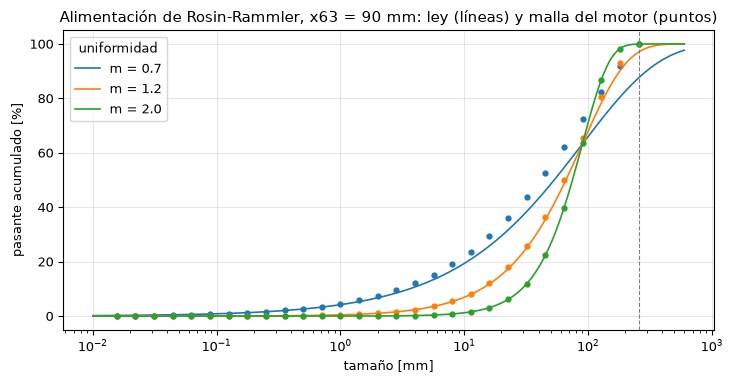

In [6]:
# Grafique la curva de los textos y los valores de la malla del motor para cada uniformidad
sizes = np.logspace(-2, np.log10(600), 300)
fig, ax = plt.subplots()
for m, feed in feeds.items():
    line, = ax.plot(sizes, [law_passing(x, X63, m) * 100 for x in sizes], lw=1.2, label=f"m = {m}")
    ax.plot(edges, np.array(feed.passing) * 100, "o", ms=3.5, color=line.get_color())
ax.axvline(256, color="grey", ls="--", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel("tamaño [mm]")
ax.set_ylabel("pasante acumulado [%]")
ax.set_title("Alimentación de Rosin-Rammler, x63 = 90 mm: ley (líneas) y malla del motor (puntos)")
ax.legend(title="uniformidad")
fig.tight_layout()
plt.show()

Los puntos se separan de su línea a la derecha, donde la ley aún tiene masa sobre la línea punteada de 256 mm y la curva del motor ya llegó a 100 por ciento: los puntos de la alimentación ancha quedan visiblemente sobre su línea en casi todo el rango, los de la de S01 apenas, y los de la uniforme no se separan. Lo que la figura no dice es qué F80 mediría una planta; eso depende de si la alimentación real tiene un tamaño máximo de 256 mm, un hecho que el punto de operación debe llevar. Importa más para el cono secundario, donde el tamaño máximo de la alimentación es del orden de la boca del chancador.

**Paso 2, cómo mueve x63 al F80 con m fijo.** El último paso varía el tamaño característico de una alimentación con la uniformidad de S01, de 30 a 250 mm, y pone el F80 del motor frente al de los textos. Muestra desde dónde importa el truncamiento.

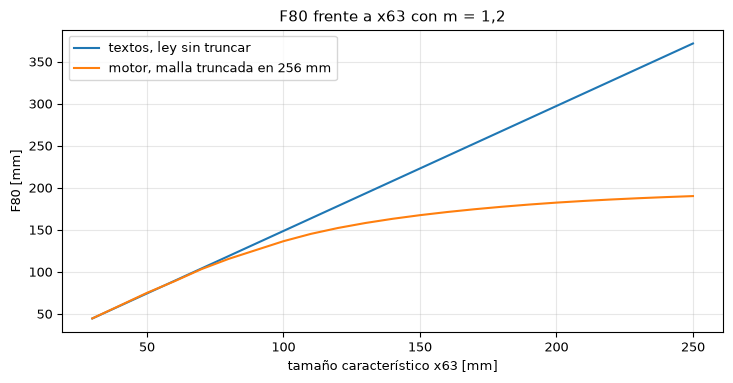

F80 con x63 = 250 mm: motor 190.2 mm, textos 371.7 mm


In [7]:
# Barra x63 con la uniformidad de S01: F80 del motor frente a F80 de los textos
x63_values = np.linspace(30, 250, 23)
engine_f80 = [size_at_passing(make_feed(edges, x, M), 0.8) for x in x63_values]
textbook_f80 = [law_size_at(0.8, x, M) for x in x63_values]
fig, ax = plt.subplots()
ax.plot(x63_values, textbook_f80, label="textos, ley sin truncar")
ax.plot(x63_values, engine_f80, label="motor, malla truncada en 256 mm")
ax.set_xlabel("tamaño característico x63 [mm]")
ax.set_ylabel("F80 [mm]")
ax.set_title("F80 frente a x63 con m = 1,2")
ax.legend()
fig.tight_layout()
plt.show()
print("F80 con x63 = 250 mm: motor", round(engine_f80[-1], 1), "mm, textos", round(textbook_f80[-1], 1), "mm")

Bajo un x63 de unos 60 mm las dos líneas son casi la misma línea. Sobre él se separan, y con x63 = 250 mm el F80 del motor es 190,2 mm frente a un valor de los textos de 371,7 mm, porque entonces la alimentación tiene 35,7 por ciento de su masa más allá de la malla. La curva del motor se aplana: subir más x63 apenas sube su F80, ya que solo cuenta la parte bajo 256 mm. Quien fija una alimentación gruesa en el estudio debe leer el F80 que informa el estudio, no el que sugiere la ley, y debe tratar una alimentación cuya ley pone mucha masa sobre 256 mm como fuera de lo que la malla puede representar.

## Resultados

**Respuesta:** x63 fija la escala de la alimentación y m su dispersión, y ambos mueven F80: con x63 = 90 mm el F80 de forma cerrada es 177,62, 133,80 y 114,18 mm para m = 0,7, 1,2 y 2,0. El motor informa 117,66, 126,03 y 115,62 mm, porque su malla termina en 256 mm y la masa de la ley sobre ese tamaño (12,50, 3,00 y 0,03 por ciento) se descarta y el resto se renormaliza. Para la alimentación de referencia de S01 el F80 del motor es 126,03 mm, 7,77 mm bajo los 133,80 mm de los textos, y con x63 = 250 mm la diferencia crece a 181,5 mm.

Las figuras separan dos cosas que se parecen. La primera muestra los puntos del motor sobre la línea de la ley hasta el corte, de modo que la discretización en sí es sana. La segunda muestra el corte creciendo con x63. Un validador concluiría que el F80 en este producto es el F80 de la alimentación tal como la ve la malla, y que una alimentación con más de unos pocos por ciento de su masa sobre 256 mm necesita otro tamaño máximo. El notebook siguiente separa el error de interpolación de este error de truncamiento.

## Resumen

Una alimentación de Rosin-Rammler son dos números, y el motor los convierte en 28 masas de clase. El F80 de los textos y el del motor difieren por la masa más allá del extremo de 256 mm de la malla, que es 3 por ciento para la alimentación de referencia y crece rápido con x63 y con una dispersión ancha. Leer F80 del motor, nunca de la fórmula, mantiene el número coherente con el tamaño de producto calculado en la misma malla. El notebook 02 muestra qué tan bien lee un tamaño de la malla la propia interpolación.

## Referencias

- Rosin, P., Rammler, E. (1933), The laws governing the fineness of powdered coal, Journal of the Institute of Fuel 7, 29-36. https://cir.nii.ac.jp/crid/1572543024341127296
- Whiten, W. J. (1972), The simulation of crushing plants with models developed using multiple spline regression, Journal of the South African Institute of Mining and Metallurgy 72(10), 257-264. https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193